# Graph DiffusionとPersonalized PageRank

## 概要

Graph Diffusionは、グラフ上を異なる歩数だけ移動した結果を重み付きで足し合わせる方法である。Personalized PageRank（PPR）は、その重みに幾何分布を使う。遷移行列から式を導き、3頂点の手計算、疎行列による実装、再スタート確率と出発点の比較を行う。最後にHeat Kernelとの違いを確認する。

## 実行環境

Python 3.14.6、カーネルは`wa-src(3.14.6)`である。ライブラリの版を下に記録する。セルを上から実行すると、作業ディレクトリの`105_nb_files`へSVGを保存する。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import sympy as sp
from IPython.display import Latex, SVG, display
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.linalg import expm
from scipy.sparse import csc_array, diags_array, eye_array
from scipy.sparse.linalg import spsolve
from scipy.stats import poisson

assert platform.python_version() == "3.14.6", "wa-src(3.14.6)を選択する"
print("カーネル: wa-src(3.14.6)")
print("Python:", platform.python_version())
print("OS:", platform.system(), platform.release())
for package in ("numpy", "scipy", "matplotlib", "networkx", "sympy"):
    print(f"{package}: {version(package)}")

OUT = Path("105_nb_files")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "svg.fonttype": "path"})


def sig3(value):
    """ゼロ以外は末尾のゼロを含めて有効数字3桁で表示する。"""
    return "0" if value == 0 else f"{float(value):#.3g}"


np.set_printoptions(formatter={"float_kind": sig3})
tick_format = FuncFormatter(lambda value, _: sig3(value))


def show_math(source):
    # 重要な式の \(...\) を、HTML出力でも使える $$...$$ に変換する。
    display(Latex(source.replace(r"\(", "$$").replace(r"\)", "$$")))


def save_svg(fig, name):
    """SVGを保存し、同じ図をノートブックの出力に埋め込む。"""
    target = OUT / name
    fig.savefig(target, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(target)))

カーネル: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin 25.5.0
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
networkx: 3.7
sympy: 1.14.0


## 1. ランダムウォークから拡散へ

非負の重みを持ち、孤立点のない無向グラフを扱う。隣接行列を$\mathbf{A}$、次数を$d_j=\sum_i A_{ij}$、次数行列を$\mathbf{D}=\operatorname{diag}(d_0,\ldots,d_{n-1})$とする。確率は列ベクトルで表す。

<div>

$$
\mathbf{P}=\mathbf{A}\mathbf{D}^{-1},\qquad
P_{ij}=\frac{A_{ij}}{d_j},\qquad
\sum_iP_{ij}=1.
$$

</div>

$P_{ij}$は頂点$j$から$i$への移動確率である。出発分布$\mathbf{s}\geq\mathbf{0}$、$\mathbf{1}^{\mathsf T}\mathbf{s}=1$に対し、1歩後は$\mathbf{P}\mathbf{s}$、2歩後は$\mathbf{P}^2\mathbf{s}$となる。

<div>

$$
\mathbf{S}=\sum_{k=0}^{\infty}\theta_k\mathbf{P}^k,\qquad
\mathbf{x}=\mathbf{S}\mathbf{s},\qquad
\theta_k\geq0,\quad\sum_{k=0}^{\infty}\theta_k=1.
$$

</div>

これは歩数$k$を確率$\theta_k$で選んだときの到着分布である。この定式化とPPR・Heat Kernelの関係は[原論文の第2節](https://arxiv.org/html/1911.05485v4#S2)にも記載されている。

## 2. PPRの導出

各ステップで確率$\alpha\in(0,1)$で$\mathbf{s}$へ戻り、確率$\beta=1-\alpha$で辺を移動する。$\mathbf{p}^{(0)}=\mathbf{s}$とすると、

<div>

$$
\begin{aligned}
\mathbf{p}^{(t+1)}&=\alpha\mathbf{s}+\beta\mathbf{P}\mathbf{p}^{(t)},\\
\mathbf{p}^{(1)}&=\alpha\mathbf{s}+\beta\mathbf{P}\mathbf{s},\\
\mathbf{p}^{(2)}&=\alpha\mathbf{s}+\alpha\beta\mathbf{P}\mathbf{s}+\beta^2\mathbf{P}^2\mathbf{s},\\
\mathbf{p}^{(t)}&=\alpha\sum_{k=0}^{t-1}\beta^k\mathbf{P}^k\mathbf{s}
+\beta^t\mathbf{P}^t\mathbf{s}.
\end{aligned}
$$

</div>

最後の項の成分和は$\beta^t$であり、ゼロへ近づく。極限$\mathbf{p}$について、

<div>

$$
\begin{aligned}
\mathbf{p}&=\alpha\mathbf{s}+\beta\mathbf{P}\mathbf{p},\\
(\mathbf{I}-\beta\mathbf{P})\mathbf{p}&=\alpha\mathbf{s},\\
\mathbf{p}&=\alpha(\mathbf{I}-\beta\mathbf{P})^{-1}\mathbf{s}
=\sum_{k=0}^{\infty}\alpha\beta^k\mathbf{P}^k\mathbf{s}.
\end{aligned}
$$

</div>

$\|\beta\mathbf{P}\|_1=\beta<1$なので逆行列は存在し、解は一意である。重みは$\theta_k=\alpha\beta^k$、合計は$\alpha/(1-\beta)=1$となる。したがって、$\mathbf{p}$も非負で成分和が1の確率分布である。

## 3. 3頂点で計算する

頂点$0-1-2$をつないだグラフで、$\mathbf{s}=(1,0,0)^{\mathsf T}$とする。遷移行列と成分ごとの式は次のとおりである。

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

array([0.583, 0.333, 0.0833])


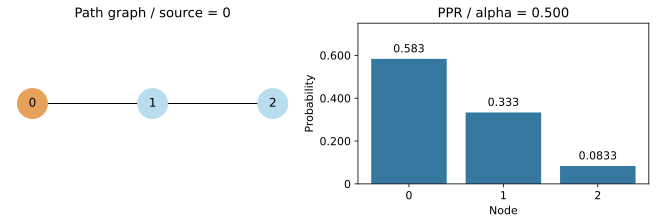

In [2]:
# 分数のまま計算し、手計算と線形方程式の解を照合する。
P3 = sp.Matrix([[0, sp.Rational(1, 2), 0],
                [1, 0, 1],
                [0, sp.Rational(1, 2), 0]])
s3 = sp.Matrix([1, 0, 0])
show_math(r"\(\mathbf{P}=" + sp.latex(P3) + r"\)")
show_math(r"\(\begin{aligned}"
          r"p_0&=\alpha+\beta p_1/2,&"
          r"p_1&=\beta(p_0+p_2),&p_2&=\beta p_1/2.\\"
          r"p_0+p_2&=\alpha+\beta p_1,\\"
          r"p_1&=\alpha\beta+\beta^2p_1,\\"
          r"p_1&=\frac{\alpha\beta}{1-\beta^2}"
          r"=\frac{(1-\beta)\beta}{(1-\beta)(1+\beta)}"
          r"=\frac{\beta}{1+\beta},\\"
          r"p_2&=\frac{\beta^2}{2(1+\beta)},\qquad "
          r"p_0=\alpha+\frac{\beta^2}{2(1+\beta)}."
          r"\end{aligned}\)")

alpha3 = sp.Rational(1, 2)
beta3 = 1 - alpha3
exact3 = (sp.eye(3) - beta3 * P3).inv() * (alpha3 * s3)
assert exact3 == sp.Matrix([sp.Rational(7, 12), sp.Rational(1, 3),
                           sp.Rational(1, 12)])
show_math(r"\(\alpha=\frac12,\quad p_1=\frac{1/2}{1+1/2}=\frac13,"
          r"\quad p_2=\frac12\frac{1/3}{2}=\frac1{12},"
          r"\quad p_0=\frac12+\frac1{12}=\frac7{12}.\)")
show_math(r"\(\mathbf{p}=" + sp.latex(exact3) + r"\)")
p3 = np.array(exact3, dtype=float).ravel()
pprint(p3)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
nx.draw_networkx(nx.path_graph(3), pos={i: (i, 0) for i in range(3)},
                 ax=axes[0], node_color=["#e6a15a", "#b9dcee", "#b9dcee"],
                 node_size=900)
axes[0].set_title("Path graph / source = 0")
axes[0].set_axis_off()
axes[1].bar(range(3), p3, color="#3679a0")
axes[1].bar_label(axes[1].containers[0], labels=[sig3(x) for x in p3], padding=4)
axes[1].set(xlabel="Node", ylabel="Probability", title="PPR / alpha = 0.500",
            ylim=(0, 0.750), xticks=range(3))
axes[1].yaxis.set_major_formatter(tick_format)
save_svg(fig, "01_three_node_solution.svg")

## 4. 再スタート確率と広がり

5頂点の完全グラフを2つ作り、頂点4と5を重み$0.200$の辺で結ぶ。他の辺の重みは1である。出発点は頂点0とする。通常の歩行は次第に右側へ移る。

PPRで混ぜる歩数$K$の平均は、幾何級数を微分すると求まる。

<div>

$$
\begin{aligned}
\sum_{k=0}^{\infty}\beta^k&=(1-\beta)^{-1},\\
\sum_{k=1}^{\infty}k\beta^{k-1}&=(1-\beta)^{-2},\\
\mathbb{E}[K]&=\alpha\beta\sum_{k=1}^{\infty}k\beta^{k-1}
=\frac{\alpha\beta}{(1-\beta)^2}=\frac{1-\alpha}{\alpha}.
\end{aligned}
$$

</div>

$\alpha$が大きいほど短い歩行の重みが増える。私は、$\alpha$の値だけを見るより、この平均歩数で考えるほうが分かりやすい。

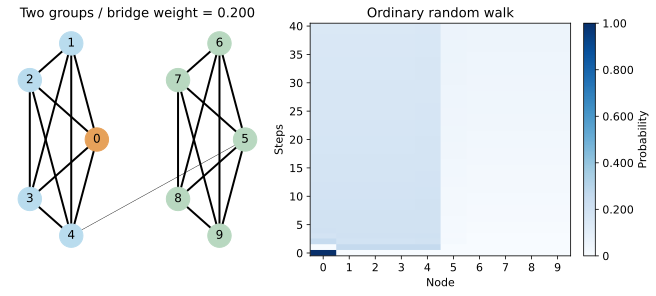

In [3]:
G = nx.disjoint_union(nx.complete_graph(5), nx.complete_graph(5))
nx.set_edge_attributes(G, 1, "weight")
G.add_edge(4, 5, weight=0.200)
nodes = list(range(10))
A = nx.to_scipy_sparse_array(G, nodelist=nodes, weight="weight", format="csc")
degrees = np.asarray(A.sum(axis=0)).ravel()
assert np.all(degrees > 0)  # 本例には孤立点を含めない。
P = csc_array(A @ diags_array(1 / degrees))
n = len(nodes)
s = np.zeros(n)
s[0] = 1
assert np.allclose(np.asarray(P.sum(axis=0)).ravel(), 1)

# 2つの集団を離して配置し、以後の図でも位置を固定する。
angle = np.linspace(0, 2 * np.pi, 5, endpoint=False)
pos = {i: (np.cos(angle[i]), np.sin(angle[i])) for i in range(5)}
pos.update({i + 5: (4 + np.cos(angle[i]), np.sin(angle[i])) for i in range(5)})

walk = [s.copy()]
for _ in range(40):
    walk.append(P @ walk[-1])
walk = np.asarray(walk)
assert np.allclose(walk.sum(axis=1), 1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
nx.draw_networkx(G, pos=pos, ax=axes[0], node_size=550,
                 node_color=["#e6a15a"] + ["#b9dcee"] * 4 + ["#b8d8c0"] * 5,
                 width=[2 * G[u][v]["weight"] for u, v in G.edges])
axes[0].set_title("Two groups / bridge weight = 0.200")
axes[0].set_axis_off()
im = axes[1].imshow(walk, aspect="auto", origin="lower", cmap="Blues",
                    extent=(-0.500, 9.50, -0.500, 40.5), vmin=0, vmax=1)
axes[1].set(xlabel="Node", ylabel="Steps", title="Ordinary random walk",
            xticks=nodes)
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
fig.colorbar(im, ax=axes[1], label="Probability", format=tick_format)
save_svg(fig, "02_graph_and_random_walk.svg")

計算では逆行列を作らず、$(\mathbf{I}-\beta\mathbf{P})\mathbf{p}=\alpha\mathbf{s}$を`scipy.sparse.linalg.spsolve`で解く。3枚の図の色は同じ範囲にそろえる。

{'alpha': '0.0500', '右側の確率': '0.125', '平均歩数': '19.0'}
{'alpha': '0.150', '右側の確率': '0.0419', '平均歩数': '5.67'}
{'alpha': '0.500', '右側の確率': '0.00513', '平均歩数': '1.00'}


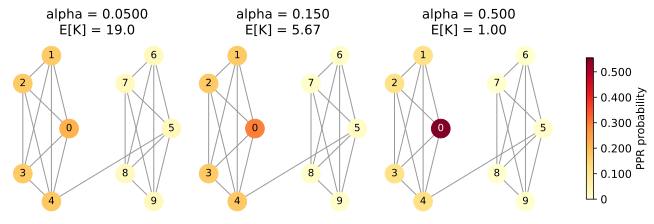

In [4]:
def ppr_solve(transition, source, alpha):
    """列確率行列からPPRを疎な連立一次方程式として求める。"""
    if not 0 < alpha < 1:
        raise ValueError("alphaは0と1の間にする")
    coefficient = eye_array(transition.shape[0], format="csc") - (1 - alpha) * transition
    return spsolve(coefficient, alpha * source)


alphas = (0.0500, 0.150, 0.500)
profiles = {alpha: ppr_solve(P, s, alpha) for alpha in alphas}
for alpha, probability in profiles.items():
    assert np.all(probability >= 0)
    assert np.isclose(probability.sum(), 1)
    assert np.linalg.norm(probability - alpha * s - (1 - alpha) * (P @ probability), 1) < 1.00e-12
    pprint({"alpha": sig3(alpha), "平均歩数": sig3((1 - alpha) / alpha),
            "右側の確率": sig3(probability[5:].sum())})

fig, axes = plt.subplots(1, 3, figsize=(9, 3), layout="constrained")
vmax = max(float(p.max()) for p in profiles.values())
for ax, alpha in zip(axes, alphas):
    probability = profiles[alpha]
    nx.draw_networkx(G, pos=pos, ax=ax, node_size=350, node_color=probability,
                     cmap=plt.cm.YlOrRd, vmin=0, vmax=vmax,
                     edge_color="#999999", with_labels=False)
    # 濃い色の頂点では文字を白くして、番号を読めるようにする。
    for node in nodes:
        nx.draw_networkx_labels(G, pos, labels={node: str(node)}, ax=ax,
                                font_size=10,
                                font_color="white" if probability[node] / vmax > 0.550 else "black")
    ax.set_title(f"alpha = {sig3(alpha)}\nE[K] = {sig3((1 - alpha) / alpha)}")
    ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, vmax), cmap="YlOrRd"),
             ax=list(axes), label="PPR probability", format=tick_format, shrink=0.800)
save_svg(fig, "03_restart_probability.svg")

## 5. 反復計算と収束

誤差$\mathbf{e}^{(t)}=\mathbf{p}^{(t)}-\mathbf{p}$を取ると、再スタート項は消える。ここで$\|\mathbf{v}\|_1=\sum_i|v_i|$である。

<div>

$$
\begin{aligned}
\mathbf{e}^{(t+1)}&=\beta\mathbf{P}\mathbf{e}^{(t)},\\
\|\mathbf{e}^{(t)}\|_1&\leq\beta^t\|\mathbf{s}-\mathbf{p}\|_1\leq2\beta^t.
\end{aligned}
$$

</div>

連結性や通常の歩行の収束に依存せず、PPRの反復は収束する。停止判定には残差$\mathbf{r}=\mathbf{q}-\alpha\mathbf{s}-\beta\mathbf{P}\mathbf{q}$を使う。$(\mathbf{I}-\beta\mathbf{P})(\mathbf{q}-\mathbf{p})=\mathbf{r}$より、誤差は$\|\mathbf{q}-\mathbf{p}\|_1\leq\sum_{k\geq0}\beta^k\|\mathbf{r}\|_1=\|\mathbf{r}\|_1/\alpha$で抑えられる。

[NetworkX](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html)の`alpha`は移動を続ける確率なので、ここでは`1 - alpha`を渡す。直接解、反復解、NetworkXの3通りを照合する。

{'L1誤差': '7.27e-12', 'NetworkXとの差': '1.34e-12', 'alpha': '0.0500', '反復回数': 347}
{'L1誤差': '8.07e-12', 'NetworkXとの差': '4.78e-13', 'alpha': '0.150', '反復回数': 128}
{'L1誤差': '4.82e-12', 'NetworkXとの差': '5.06e-14', 'alpha': '0.500', '反復回数': 31}


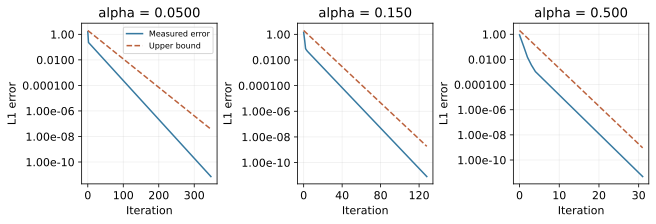

In [5]:
def ppr_iterate(transition, source, alpha, tol=1.00e-11, max_iter=5000):
    probability = source.copy()
    history = [probability.copy()]
    for _ in range(max_iter):
        probability = alpha * source + (1 - alpha) * (transition @ probability)
        history.append(probability.copy())
        residual = probability - alpha * source - (1 - alpha) * (transition @ probability)
        if np.linalg.norm(residual, 1) / alpha <= tol:
            return probability, np.asarray(history)
    raise RuntimeError("指定回数以内に収束しなかった")


fig, axes = plt.subplots(1, 3, figsize=(9, 3), layout="constrained")
for ax, alpha in zip(axes, alphas):
    direct = profiles[alpha]
    iterative, history = ppr_iterate(P, s, alpha)
    reference = nx.pagerank(G, alpha=1 - alpha,
                            personalization={i: float(s[i]) for i in nodes},
                            tol=1.00e-14, max_iter=5000, weight="weight")
    reference_array = np.array([reference[i] for i in nodes])
    error = np.linalg.norm(history - direct, ord=1, axis=1)
    steps = np.arange(len(history))
    bound = 2 * (1 - alpha) ** steps
    np.testing.assert_allclose(iterative, direct, atol=1.00e-11, rtol=0)
    np.testing.assert_allclose(reference_array, direct, atol=1.00e-11, rtol=0)
    assert np.all(error <= bound + 1.00e-14)
    pprint({"alpha": sig3(alpha), "反復回数": len(history) - 1,
            "L1誤差": sig3(error[-1]),
            "NetworkXとの差": sig3(np.linalg.norm(reference_array - direct, 1))})
    ax.semilogy(steps, error, color="#3679a0", label="Measured error")
    ax.semilogy(steps, bound, "--", color="#bb613c", label="Upper bound")
    ax.set(xlabel="Iteration", ylabel="L1 error", title=f"alpha = {sig3(alpha)}")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    ax.yaxis.set_major_formatter(tick_format)
    ax.grid(alpha=0.200)
axes[0].legend(fontsize=8)
save_svg(fig, "04_iteration_convergence.svg")

疎行列とベクトルの積による1回の更新は$O(|E|+n)$である。図示のため履歴を保存しているが、大きなグラフでは最新のベクトルだけを保持すればよい。

## 6. 出発分布を変える

$\mathbf{s}$を頂点0、頂点9、一様分布に変える。同じグラフでも、PPRは出発分布に応じた順位になる。推薦では閲覧履歴などを正規化して$\mathbf{s}$に置けるが、この値は購入確率ではなく、グラフ上の到着確率である。

Source 0（頂点0から9）
array([0.290, 0.167, 0.167, 0.167, 0.168, 0.0130, 0.00724, 0.00724,
       0.00724, 0.00724])
Source 9（頂点0から9）
array([0.00724, 0.00724, 0.00724, 0.00724, 0.0130, 0.168, 0.167, 0.167,
       0.167, 0.290])
Uniform（頂点0から9）
array([0.0991, 0.0991, 0.0991, 0.0991, 0.103, 0.103, 0.0991, 0.0991,
       0.0991, 0.0991])


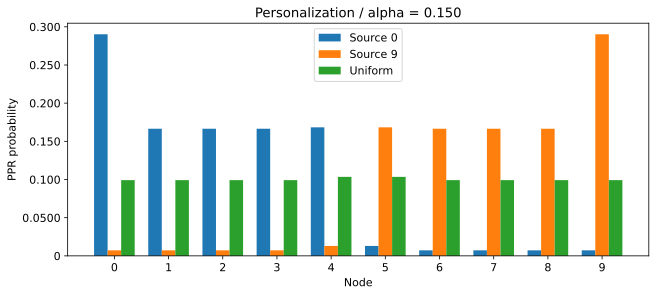

In [6]:
alpha = 0.150
s_right = np.zeros(n)
s_right[9] = 1
sources = {"Source 0": s, "Source 9": s_right, "Uniform": np.ones(n) / n}
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
width = 0.250
for offset, (label, source) in enumerate(sources.items()):
    probability = ppr_solve(P, source, alpha)
    assert np.isclose(probability.sum(), 1)
    ax.bar(np.arange(n) + (offset - 1) * width, probability, width=width, label=label)
    # 配列の順番は頂点0から9である。同値の頂点に細かな順位は付けない。
    print(f"{label}（頂点0から9）")
    pprint(probability)
ax.set(xlabel="Node", ylabel="PPR probability", xticks=nodes,
       title="Personalization / alpha = 0.150")
ax.yaxis.set_major_formatter(tick_format)
ax.legend()
save_svg(fig, "05_personalization.svg")

## 7. Heat Kernelとの比較

ここでは$\mathbf{L}=\mathbf{I}-\mathbf{P}$を使う。これは次数で正規化した確率の拡散作用素であり、$\mathbf{D}-\mathbf{A}$とは異なる。連続時間の式から、

<div>

$$
\begin{aligned}
\frac{d\mathbf{x}(\tau)}{d\tau}&=-\mathbf{L}\mathbf{x}(\tau),\quad\mathbf{x}(0)=\mathbf{s},\\
\mathbf{x}(\tau)&=e^{-\tau(\mathbf{I}-\mathbf{P})}\mathbf{s}
=e^{-\tau}e^{\tau\mathbf{P}}\mathbf{s}\\
&=\sum_{k=0}^{\infty}e^{-\tau}\frac{\tau^k}{k!}\mathbf{P}^k\mathbf{s}.
\end{aligned}
$$

</div>

歩数の重みは平均$\tau$のポアソン分布になる。$\tau=(1-\alpha)/\alpha$にそろえても、幾何分布とは重みが違うので到着分布は一致しない。[Gasteigerら（2019）](https://arxiv.org/abs/1911.05485)で挙げられた2種類の拡散を、同じグラフで比較する。

{'Heatの出発点確率': '0.192',
 'PPRの出発点確率': '0.290',
 '分布間のL1距離': '0.198',
 '平均歩数': '5.67'}


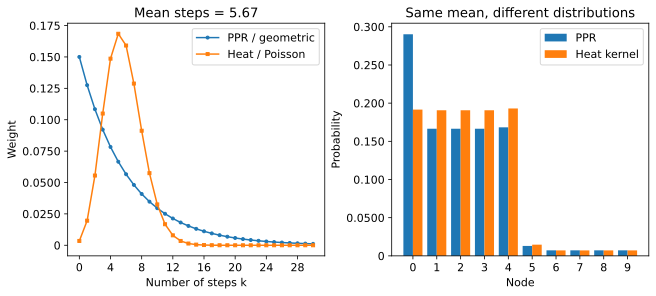

数式の手計算、3通りのPPR、級数展開の照合が完了した。


In [7]:
alpha = 0.150
tau = (1 - alpha) / alpha
ppr = profiles[alpha]
# 10頂点なので行列指数を直接計算する。大規模ならexpm_multiplyを使う。
heat = expm(-tau * (np.eye(n) - P.toarray())) @ s
assert np.all(heat >= -1.00e-14)
assert np.isclose(heat.sum(), 1)

# 無限和の近似を独立に計算し、行列指数とPPRの直接解を確かめる。
k_check = np.arange(501)
weights_ppr = alpha * (1 - alpha) ** k_check
weights_heat = poisson.pmf(k_check, mu=tau)
power = s.copy()
series_ppr, series_heat = np.zeros(n), np.zeros(n)
for w_ppr, w_heat in zip(weights_ppr, weights_heat):
    series_ppr += w_ppr * power
    series_heat += w_heat * power
    power = P @ power
np.testing.assert_allclose(series_ppr, ppr, atol=1.00e-12, rtol=0)
np.testing.assert_allclose(series_heat, heat, atol=1.00e-12, rtol=0)
assert np.isclose(k_check @ weights_ppr, tau)
assert np.isclose(k_check @ weights_heat, tau)
pprint({"平均歩数": sig3(tau), "PPRの出発点確率": sig3(ppr[0]),
        "Heatの出発点確率": sig3(heat[0]),
        "分布間のL1距離": sig3(np.linalg.norm(ppr - heat, 1))})

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
# 左図は歩数30までを表示する。右図の計算にこの打ち切りは使わない。
k = np.arange(31)
axes[0].plot(k, weights_ppr[:31], "o-", label="PPR / geometric", markersize=3)
axes[0].plot(k, weights_heat[:31], "s-", label="Heat / Poisson", markersize=3)
axes[0].set(xlabel="Number of steps k", ylabel="Weight", title=f"Mean steps = {sig3(tau)}")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].bar(np.arange(n) - 0.200, ppr, width=0.400, label="PPR")
axes[1].bar(np.arange(n) + 0.200, heat, width=0.400, label="Heat kernel")
axes[1].set(xlabel="Node", ylabel="Probability", xticks=nodes,
            title="Same mean, different distributions")
for ax in axes:
    ax.yaxis.set_major_formatter(tick_format)
    ax.legend()
save_svg(fig, "06_ppr_and_heat_kernel.svg")
print("数式の手計算、3通りのPPR、級数展開の照合が完了した。")

## 結論

この記事では、Graph Diffusionを歩数ごとの分布の混合として定義し、PPRの導出と計算方法を確認した。

PPRは再スタート確率で歩数の重みを調整し、出発分布で関心のある頂点を指定する。Heat Kernelはポアソン分布で歩数を混ぜるため、平均歩数が同じでも結果が異なる。実装では、遷移行列の向きと`alpha`の定義をそろえることが必要である。

参考文献：Gasteiger, Weißenberger, Günnemann, [Diffusion Improves Graph Learning](https://arxiv.org/abs/1911.05485), NeurIPS 2019。実装仕様は[NetworkXのPageRank](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html)と[SciPyのspsolve](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.spsolve.html)を参照した。